# Spatial impact-load imaging from optical displacement estimates


## 1. Problem

Infer a spatial transient pressure field from a real optically estimated plate-deflection sequence. Weak virtual work avoids direct fourth spatial differentiation of noisy displacement but introduces patch-scale averaging.

This active notebook reconstructs a complete250-frame measured plate-deflection sequence into spatial pressure. The real measurements came from280high-speed optical grid images;30unloaded reference frames and250deformed observations were processed in the isolated author implementation. A single wrong top-boundary finite-difference column index in slope integration was independently detected with an analytic linear-ramp field and minimally corrected before binding observations. All original mechanics stages were left unchanged. The unmodified complete original pipeline is also retained as a distinct comparison. The public deflection is an estimated optical observation, not displacement truth.

For a thin isotropic plate, pressure $p$ and displacement $w$ obey $D\nabla^4w+\rho h\partial_t^2w=p$, where $D=Eh^3/[12(1-\nu^2)]$. Here E is Young's modulus(Pa), hthickness(m), nuPoisson ratio, rhodensity(kg/m3), wdeflection(m) and ppressure(Pa). The local inverse uses a smooth unit-center Hermite virtual displacement v; measured curvature $\kappa=-\nabla\nabla w$ and virtual curvature $\kappa^v=-\nabla\nabla v$ enter virtual work. Pressure per patch is the sum of bending and inertia virtual work divided by the sum of v. Uniform sample area cancels. This avoids four spatial derivatives of noisy measurements.

The canonical output uses a6-frame temporal Gaussian, nearest boundary extension and20x20moving Hermitepatch; original centered/one-sided differences and valid convolution are preserved. Original coordinates call increasing row x and increasing column y; sign and physical pressure scale are retained. Full formulas and all source/provenance ambiguities are in the README, plans and test/validation.md.


## 2. Data

The public float64 deflection contains 250 frames of 79 by 97 samples in metres, derived from 280 optical grid images including 30 unloaded references. The pressure output uses valid 20 by 20 patches, yielding 250 by 60 by 78 values in Pa. The upstream optical boundary-index correction and independent hammer-force record retain distinct evidence roles.

The public observation is the complete derived optical deflection recording: 250 frames at the author's original measured-field resolution, without any pressure-based calibration. All stored values retain float64 precision.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| deflection | (1, 250, 79, 97) | float64 | Measured transverse deflection in meter; axes batch, processed time frame, row-coordinate x, column-coordinate y. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Specimen | Mirror-finished steel plate, nominal 0.3 by 0.3 | m | Outer plate dimensions; measured field covers a subset |
| Young's modulus | 190000000000 | Pa | Selected author implementation's calibrated elastic constant |
| Poisson ratio | 0.3 | dimensionless | Isotropic plate model |
| Material density | 7934.0 | kg/m^3 | Selected author implementation value |
| Plate thickness | 0.00495 | m | Selected author implementation value |
| Field spacing $\Delta$ | 0.0030065919701586503 | m | Uniform spacing along both measured-field axes, preserving source numerical calibration |
| Sampling rate | 75000.0 | Hz | Optical recording rate |
| Exposure | 0.000005 | s | Original high-speed camera exposure |
| Clock origin | First processed frame | s | Frame 0 corresponds to raw frame index 30; local clock resets to zero as in supplied example |
| Processed frames | 250 | frame | All original frames after the 30-frame reference interval |
| Camera | Phantom v2511; Sigma 50-100mm f/1.8 lens | dimensionless | Original optical recording hardware |
| Reference interval | Raw frame indices 0 through 29 | frame | Independently observed unloaded-grid reference |
| Original grid pitch | 0.00588433 | m | Physical printed-grid spacing |
| Original grid pitch in image | 5.0 | pixel | Carrier period in original optical image |
| Selected mirror-grid distance | 1.385 | m | Distance used in author code to derive the bound measured deflection |
| Optical pixel scale factor | 1.02189781 | dimensionless | Source mirror-plane calibration factor |
| Boundary | Plate edges clamped; finite measured field | dimensionless | Load inverse uses only valid internal virtual patches and does not infer exterior loads |
| Measured-field displacement gauge | Mean of two bottom 5 by 5 corner areas set to zero | m | Source optical integration convention, independently of the unknown load |
| Noise | Optical measurement noise, covariance not calibrated | m | Preserve measured fields; no synthetic noise added |
| Coordinates | Row x increasing down, column y increasing right | m | Source kinematic derivative convention; no transpose or half-pixel shift is fitted |

The dataset's descriptive text rounds density to 7900 kg/m^3 and lists a mirror-grid distance of 1.37 m. This task consistently uses the explicitly selected author implementation values above, which were used when deriving its bound observations. The difference is documented rather than silently mixing calibrations. The measured optical deflection is an observation estimate, with finite spatial resolution and integration uncertainty.


## 3. Physics

The thin-plate relation is $D\nabla^4w+\rho h\partial_t^2w=p$, with deflection $w$ in m, pressure $p$ in Pa, density $\rho$ in kg/m$^3$, thickness $h$ in m and rigidity $D=Eh^3/[12(1-\nu^2)]$ in N m. Young modulus $E$ and Poisson ratio $\nu$ are known material constants. Local Hermite virtual fields test bending and inertia through integrated work.

The observations are complete deflection fields measured during one real impact-hammer experiment on a clamped, mirror-finished steel plate. They are displacement estimates derived from the author's original optical grid recordings, with one independently justified boundary-index correction in slope integration, independently of any pressure reconstruction or force target. They are not direct displacement ground truth. Recover the signed pressure field acting on the plate. Under linear isotropic Kirchhoff-Love bending, the strong-form relation is


$$
D\left(\frac{\partial^4 w}{\partial x^4}+2\frac{\partial^4 w}{\partial x^2\partial y^2}+\frac{\partial^4 w}{\partial y^4}\right)+\rho h\frac{\partial^2w}{\partial t^2}=p,
\qquad D=\frac{E h^3}{12(1-\nu^2)}.
$$


Here $w(x,y,t)$ is transverse deflection in meters, $p(x,y,t)$ pressure in pascals, $E$ Young's modulus in pascals, $\nu$ Poisson ratio, $h$ plate thickness in meters, $\rho$ density in kilograms per cubic meter, and $D$ bending stiffness in newton meter. Coordinates $x,y$ follow increasing observed row and column, respectively; $t$ is time in seconds. Positive pressure follows the sign of the inertial term for positive deflection. The unknown is a spatial load, not a material stiffness. High-order derivatives and measurement noise make pointwise recovery unstable, while a finite recording and unmeasured exterior region limit boundary information.

The declared output is an effective pressure estimated at every valid moving square measurement patch. It uses the fixed temporal bandwidth and spatial averaging convention described here so that its physical resolution and coordinates are unambiguous: first take a Gaussian temporal average of deflection with standard deviation 80 microseconds (six recorded frames), nearest-value extension and truncation at four standard deviations. Then compute centered interior and first-order one-sided boundary differences for slopes, curvatures and acceleration. The pressure's virtual averaging patch covers 20 by 20 measured samples (physical side length $L=20\Delta$), with separable unit-center Hermite weight $v(x,y)=H(x/L)H(y/L)$ sampled at patch pixel midpoints. Here $\Delta$ is measured-field sample spacing. For $0\leq s\leq1/2$, define $u=2s$ and $H(s)=3u^2-2u^3$; for $1/2<s\leq1$, define $u=2s-1$ and $H(s)=1-3u^2+2u^3$. Both the virtual displacement and its first derivative vanish on the patch perimeter. The weak-work expression in Method Hints defines this effective pressure. These fixed output-resolution conventions should not be interpreted as recovery of an unsmoothed delta-like contact load.


## 4. Method

The direct local inverse preserves sigma-six temporal Gaussian smoothing, source finite differences, midpoint Hermite fields and valid convolution. Uniform sample area cancels in pressure estimation; the declared 9.5-sample patch-center offset must not be replaced by post-hoc shifting.

Use the virtual-fields method to move two spatial derivatives onto a smooth, compact virtual displacement. Define measured curvatures $\kappa_{xx}=-\partial^2_x w$, $\kappa_{yy}=-\partial^2_y w$ and $\kappa_{xy}=-\partial_x\partial_y w$, and virtual curvatures by the same negative derivatives of $v$. Let $a=\partial_t^2 w$ and $D_{12}=\nu D$. The effective patch pressure follows the discrete virtual-work identity


$$
\bar p=\frac{
D\sum\left(\kappa_{xx}\kappa^v_{xx}+\kappa_{yy}\kappa^v_{yy}+2\kappa_{xy}\kappa^v_{xy}\right)
+D_{12}\sum\left(\kappa_{xx}\kappa^v_{yy}+\kappa_{yy}\kappa^v_{xx}-2\kappa_{xy}\kappa^v_{xy}\right)
+\rho h\sum a v}{\sum v}.
$$


Superscript $v$ labels the virtual quantities, and each sum covers one measurement patch with uniform sampling; the common sample area cancels. This decomposition separates bending and inertia and avoids taking four noisy spatial derivatives directly. The compact Hermite virtual field eliminates unknown work at patch boundaries. The moving-patch estimate trades spatial resolution for noise sensitivity; numerical midpoint sampling also introduces finite-window quadrature error.


## 5. Results

The five preserved groups show optical kinematics, pressure and bending/inertial contributions, original/local comparisons, full and source-subregion integrated force, independent hammer trace and fresh temporal/window sensitivity. No clock shift or load-scale fitting aligns these curves.

### Evaluate fresh results and independent experimental force

The pixel-pressure reference is an independently rerun standard method, not a pressure-truth image. NCC is flattened cosine without mean subtraction; NRMSE divides RMSerror by reference dynamic range. The independent load-cell force is compared to a fixed source-declared30x30pressure subregion with exact physical sample area and original time clock. No clock shift, pressure scaling or image registration is fitted. Whole-field integration is retained too, including its substantial late-time error.

The optically estimated displacement and its local kinematics are freshly processed from public observations. The derivative order, row/column conventions, signs and units are explicit.

Canonical pressure maps and the separate bending/inertial contributions. Valid windows only are returned; patch centers include the declared9.5-sample offset, without a posthoc shift.

All original experiment comparisons remain: whole-field integration, source-declared subregion integration, independent load-cell trace. The unmodified original optical-pipeline curve is separately labeled. The weak source tail performance is visible rather than silently cropped.

Hermite virtual displacement and curvature fields are explicit local polynomials. Independent physics tests also check an accelerating rigid field and a quartic deflection. The latter reveals the preserved1%midpoint quadrature bias at20samples.

Fresh full-sequence sensitivity experiments use temporal Gaussian widths3,6,9and virtual windows12,20,28. The spatial comparison region is held fixed in physical coordinates as patch size changes. These experiments do not change the canonical6/20output or its frozen thresholds.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,importlib.util
root=Path.cwd()
if root.name=='notebooks':root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
import numpy as np
from IPython.display import display
from src.main import run
from src.preprocessing import load_observations
from src.visualization import make_figures
start=time.perf_counter();fresh=run();runtime=time.perf_counter()-start
observations=load_observations()
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:
    upstream={k:f[k] for k in ['reconstruction','uncorrected_pipeline_reconstruction']}
    hammer_time=f['measurement_time'];hammer_force=f['measurement_force']
provenance=json.loads(Path('notebooks/reference_outputs/measurements.json').read_text())
print('Fresh full250-frame runtime(s):',runtime)
print(json.dumps(provenance['source_categories'],indent=2))

Fresh full250-frame runtime(s): 3.892457200003264
{
  "published": "JOSS2022 and ExperimentalMechanics2019 provide method descriptions; their unrelated reported pressure scores are not evidence of this bound-data run.",
  "unmodified_original_pipeline": "All280 real raw frames; original defective first-row integration boundary preserved; original kinematics and VFM; separately identified comparison.",
  "corrected_original_mechanics": "Minimal acquisition-integration index correction justified independently, then unchanged original mechanics on exact bound optical displacement estimate; hidden standard reference.",
  "fresh_cleaned": "Local source actively reconstructs all250 corrected derived deflection observations."
}


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 5.013256813539885e-17,
    "force_nrmse": 0.09114770181323002
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-09
    },
    "force_nrmse": {
      "comparison": "<=",
      "boundary": 0.10026247199455302
    }
  },
  "errors": []
}


{
  "pressure_ncc_vs_upstream": 0.9999999999999999,
  "pressure_dynamic_range_nrmse_vs_upstream": 5.013256813539885e-17,
  "force_core_dynamic_range_nrmse_vs_loadcell": 0.09114770181323002,
  "force_whole_dynamic_range_nrmse_vs_loadcell": 0.3096525266497528,
  "force_core_peak_N": 363.56454375003204,
  "hammer_peak_N": 365.529085934498,
  "force_core_peak_time_ms": 1.7733333333333334,
  "hammer_peak_time_ms": 1.7773437499997158,
  "force_core_impulse_Ns": 0.21433096157970105,
  "force_hammer_impulse_Ns": 0.2318147531562455,
  "whole_force_tail_limitation": "All-field integral is retained and displayed; boundary noise and repeated differentiation create a large late-time tail.",
  "sigma_force_errors": [
    0.10944477740832989,
    0.09114770181323002,
    0.08123536410207648
  ],
  "window_force_errors": [
    0.09784727059795316,
    0.09114770181323002,
    0.08930204168130709
  ]
}


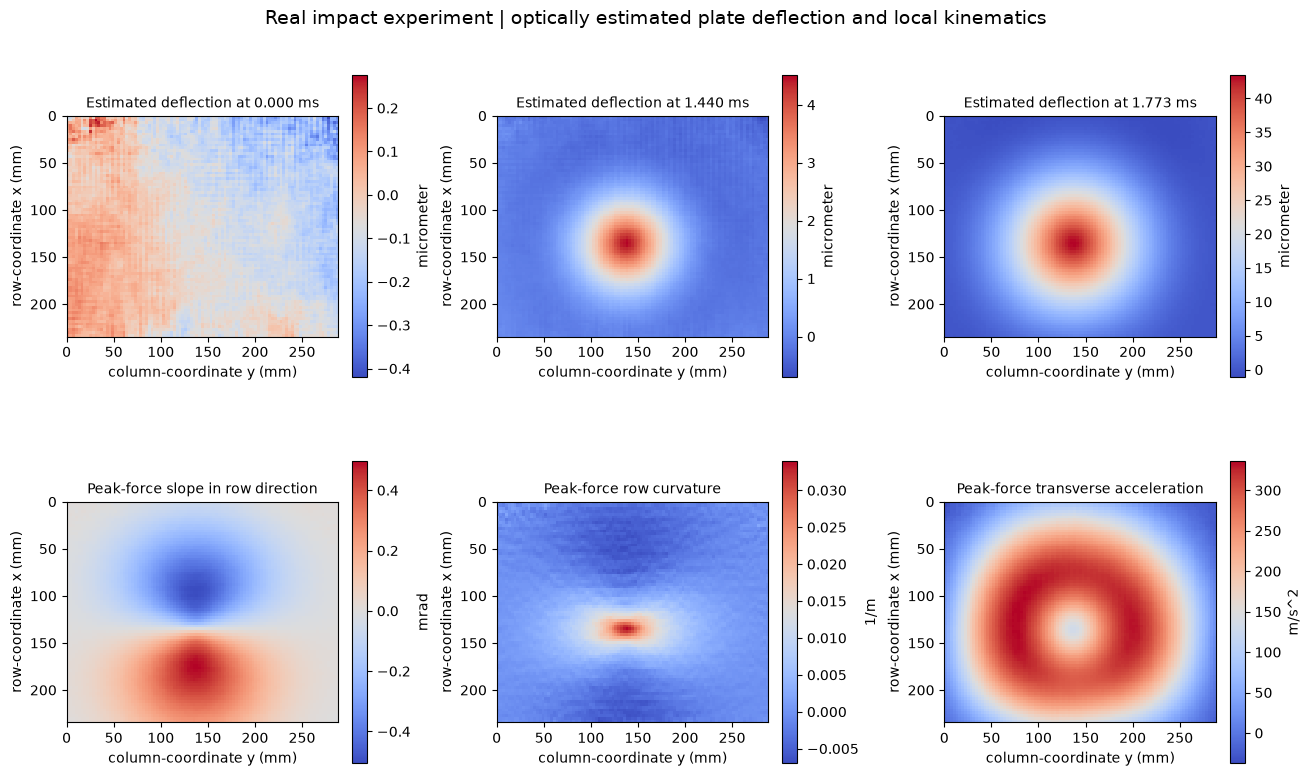

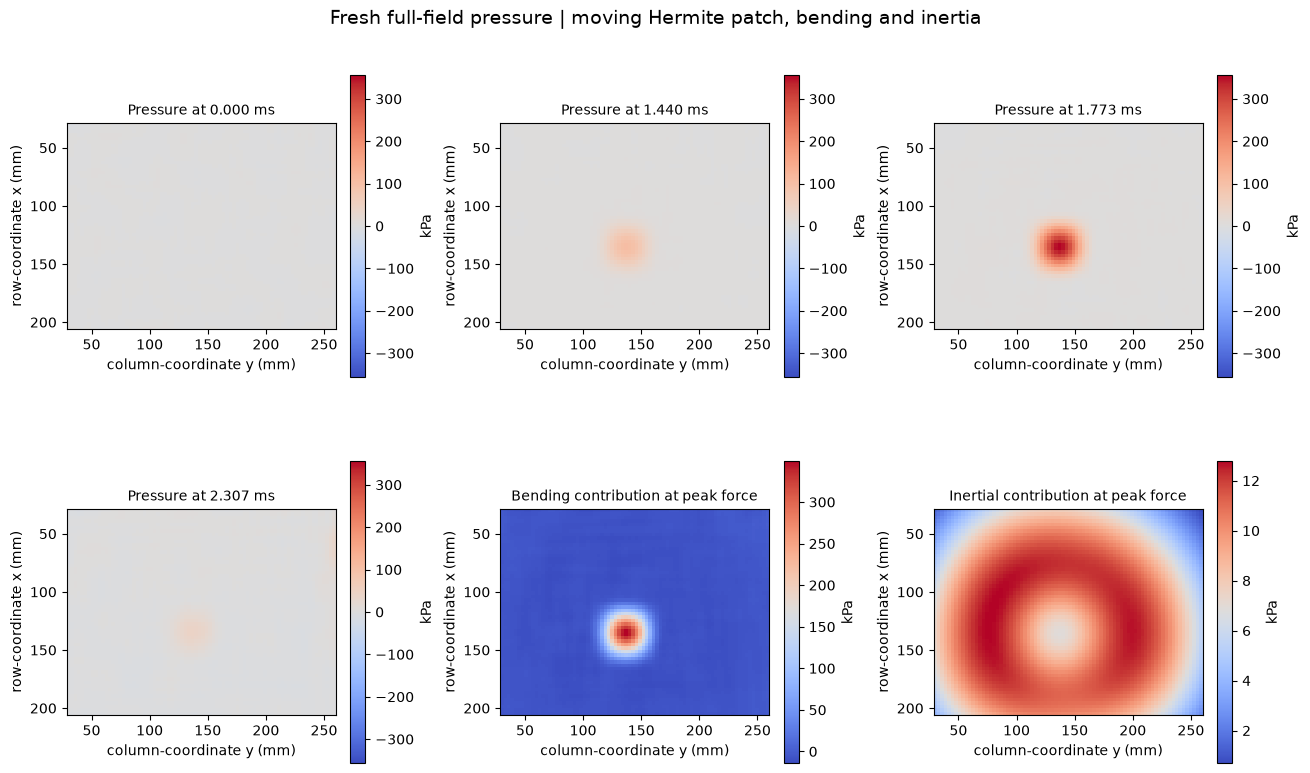

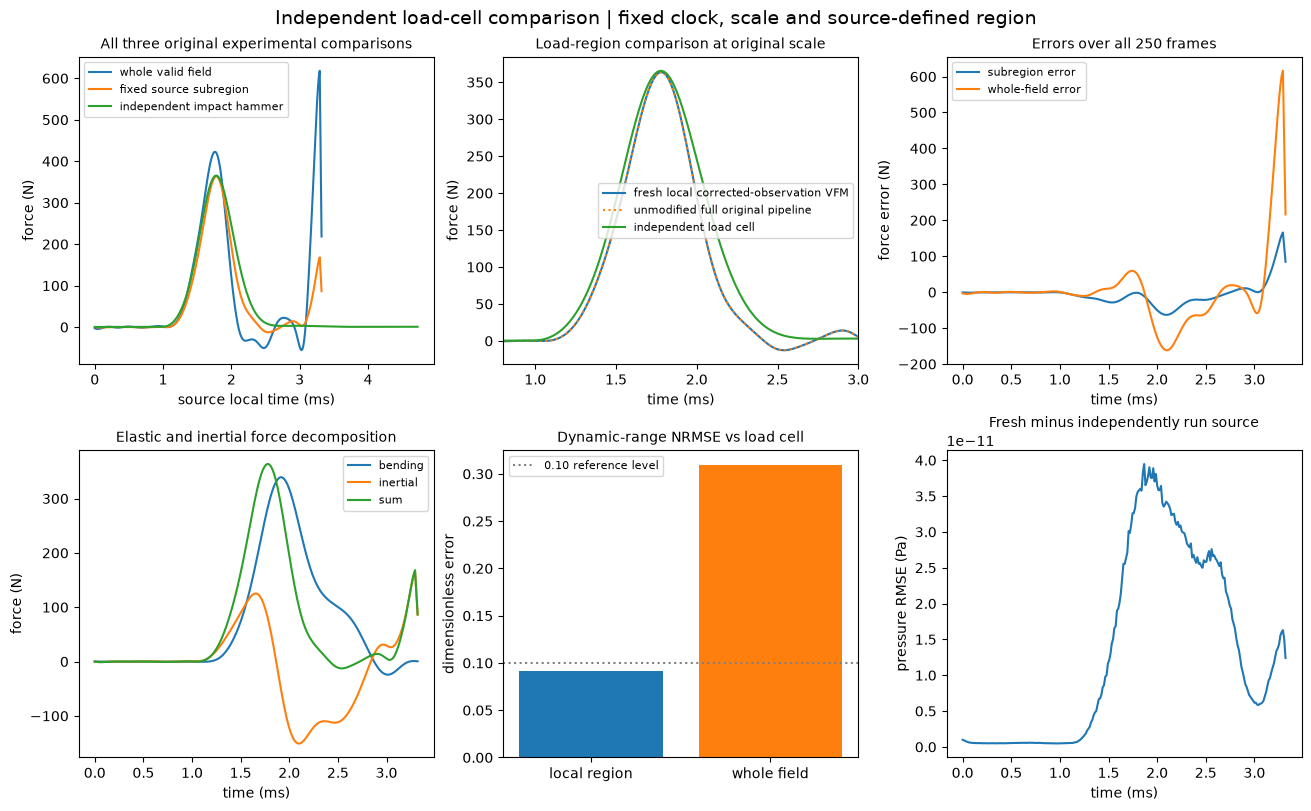

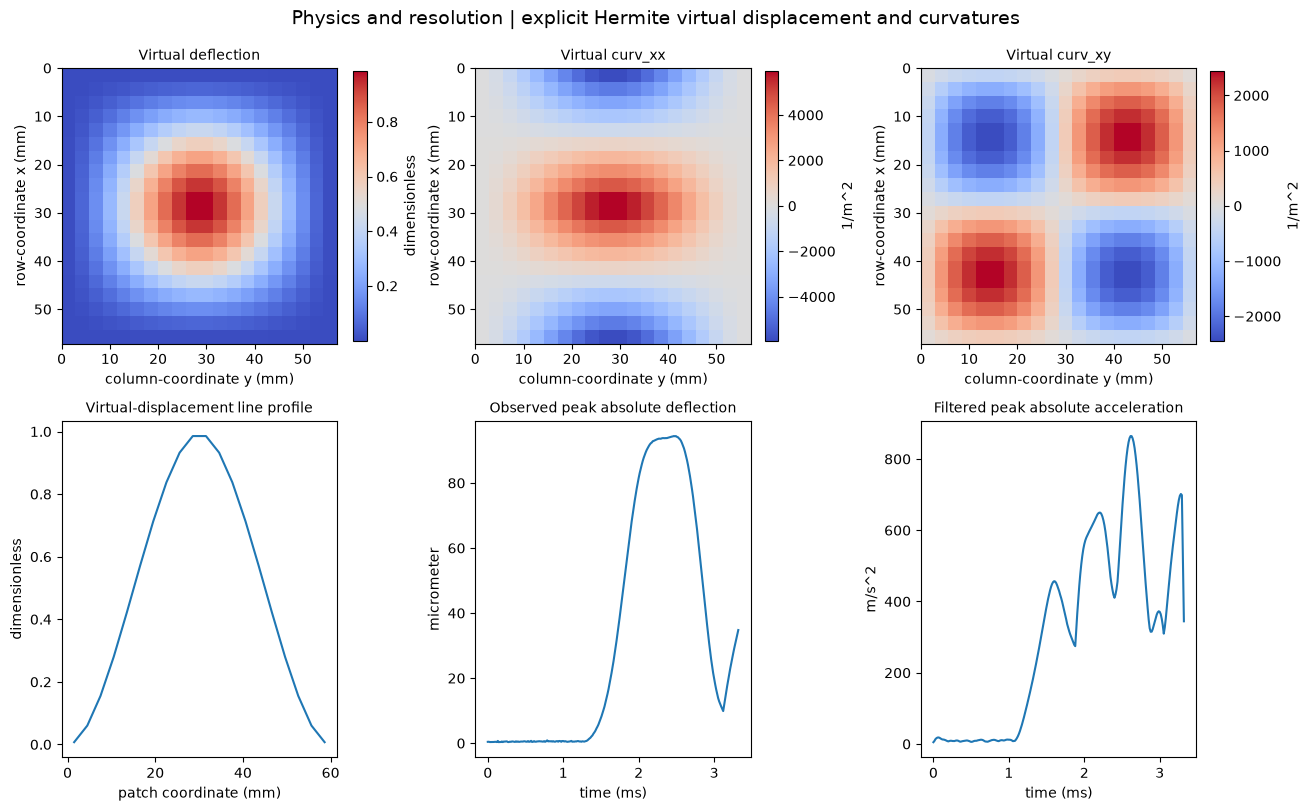

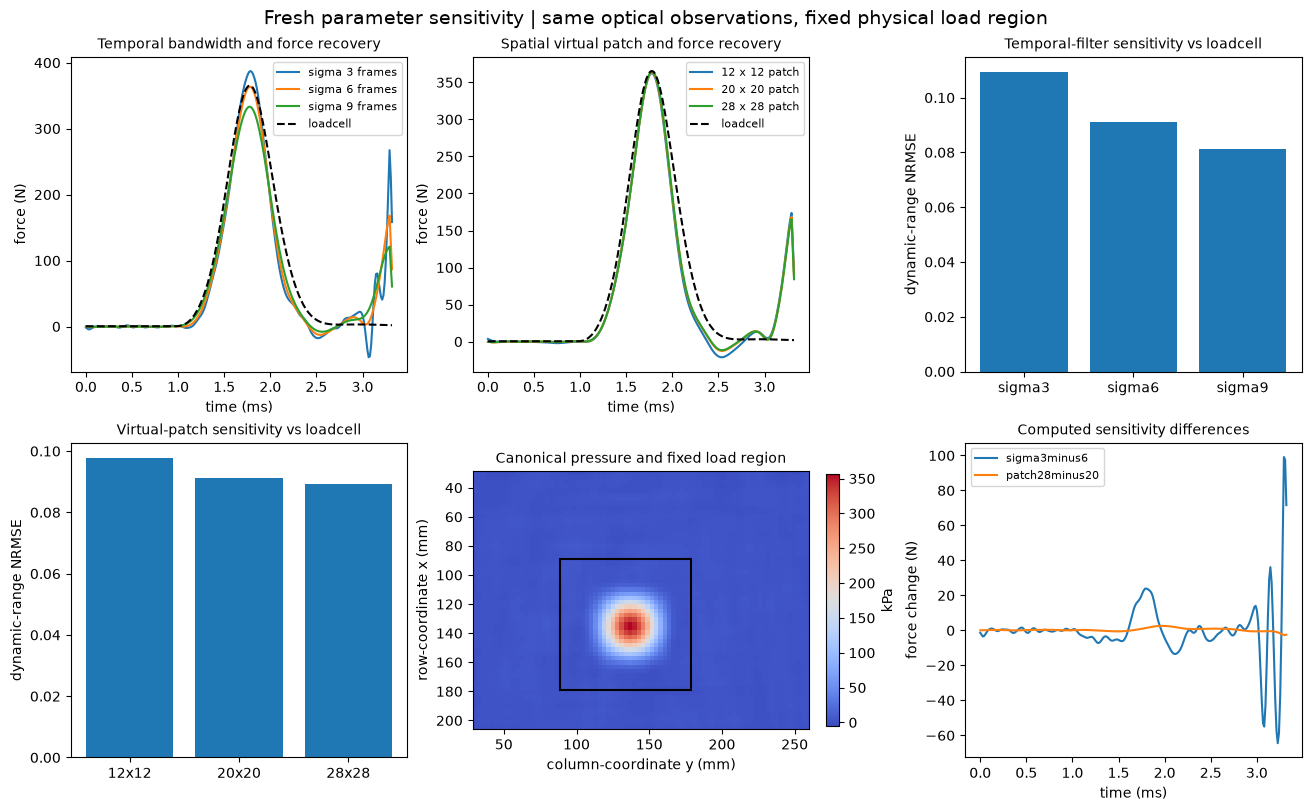

In [2]:
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert code==0
figures,numeric,measurements=make_figures(observations,fresh,upstream,hammer_time,hammer_force)
print(json.dumps(measurements,indent=2))

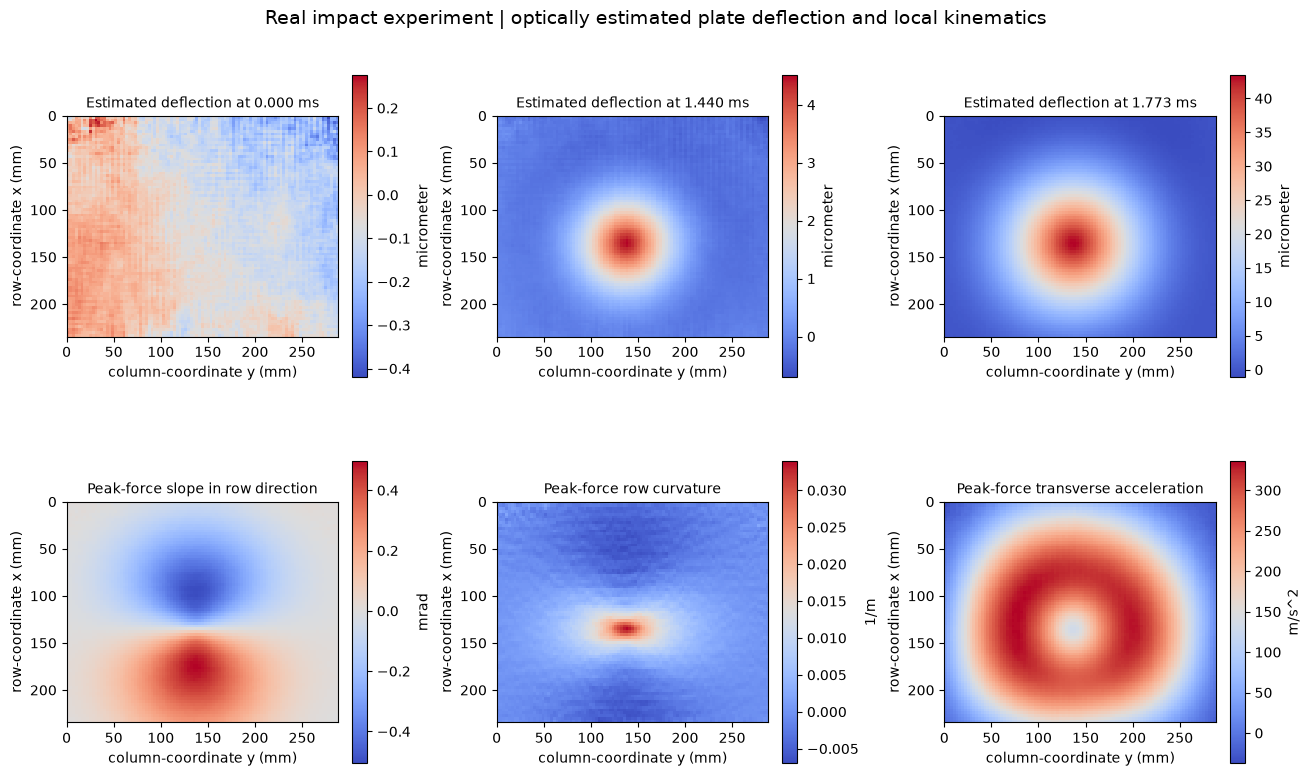

In [3]:
display(figures[0])

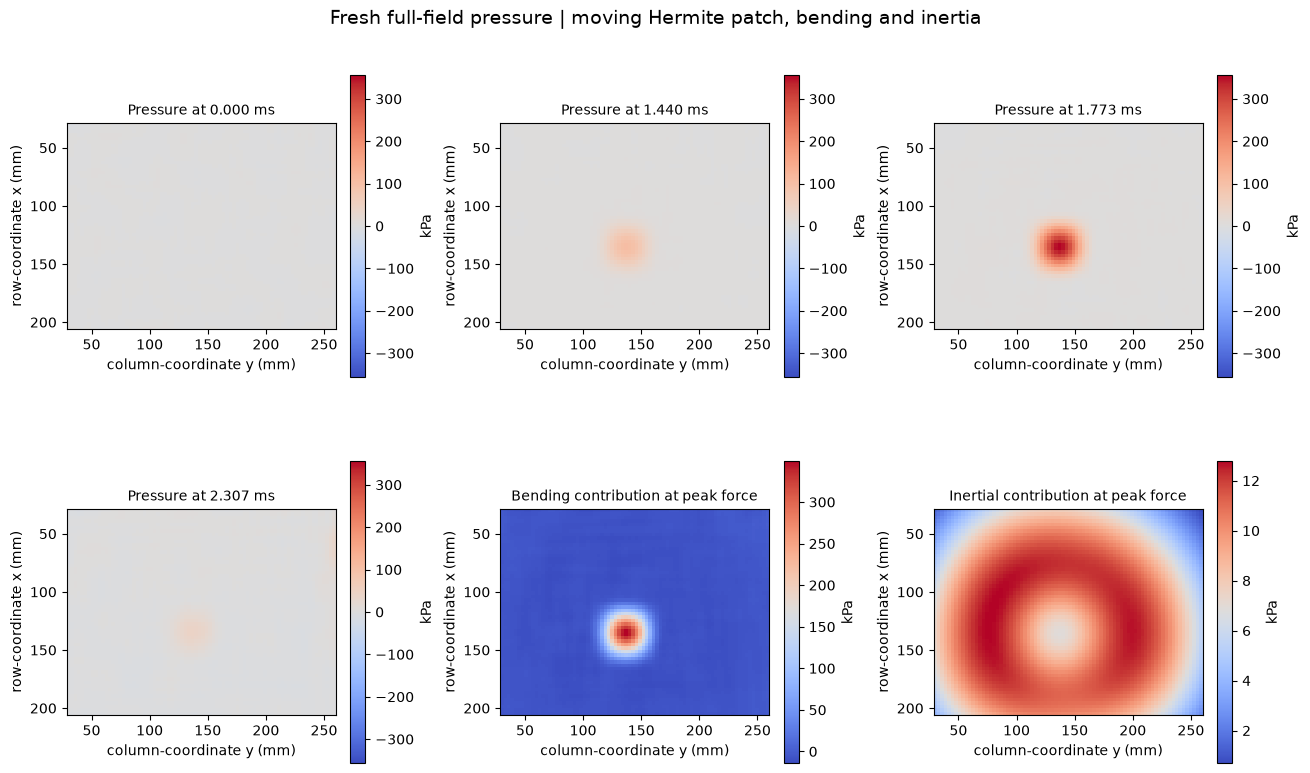

In [4]:
display(figures[1])

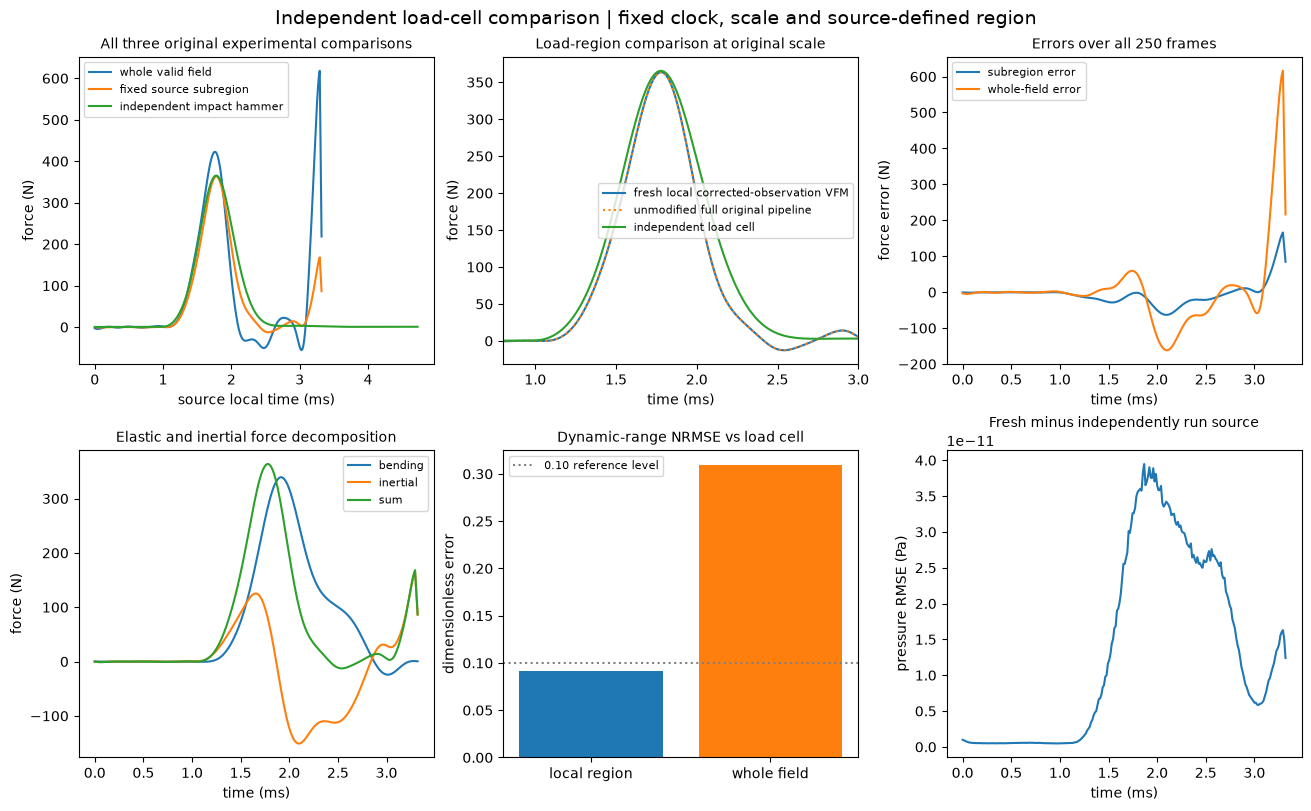

In [5]:
display(figures[2])

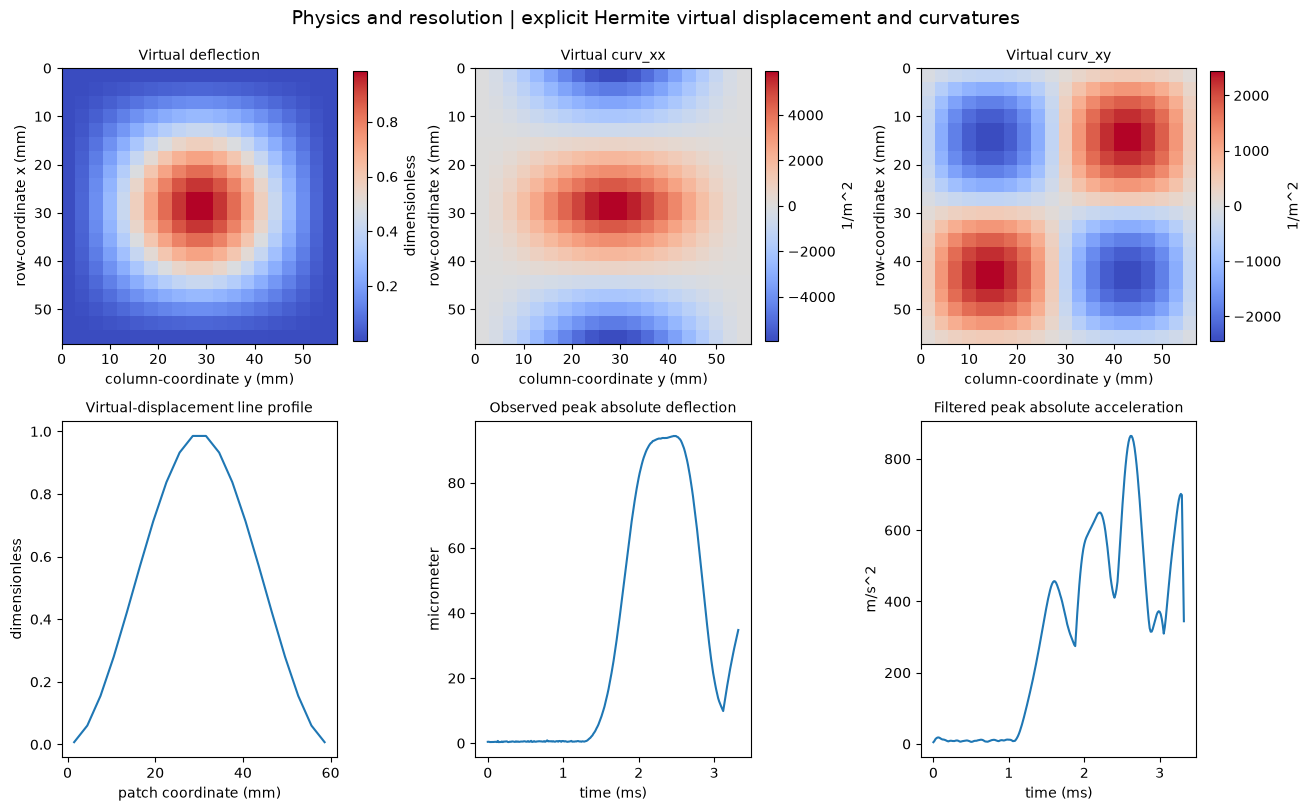

In [6]:
display(figures[3])

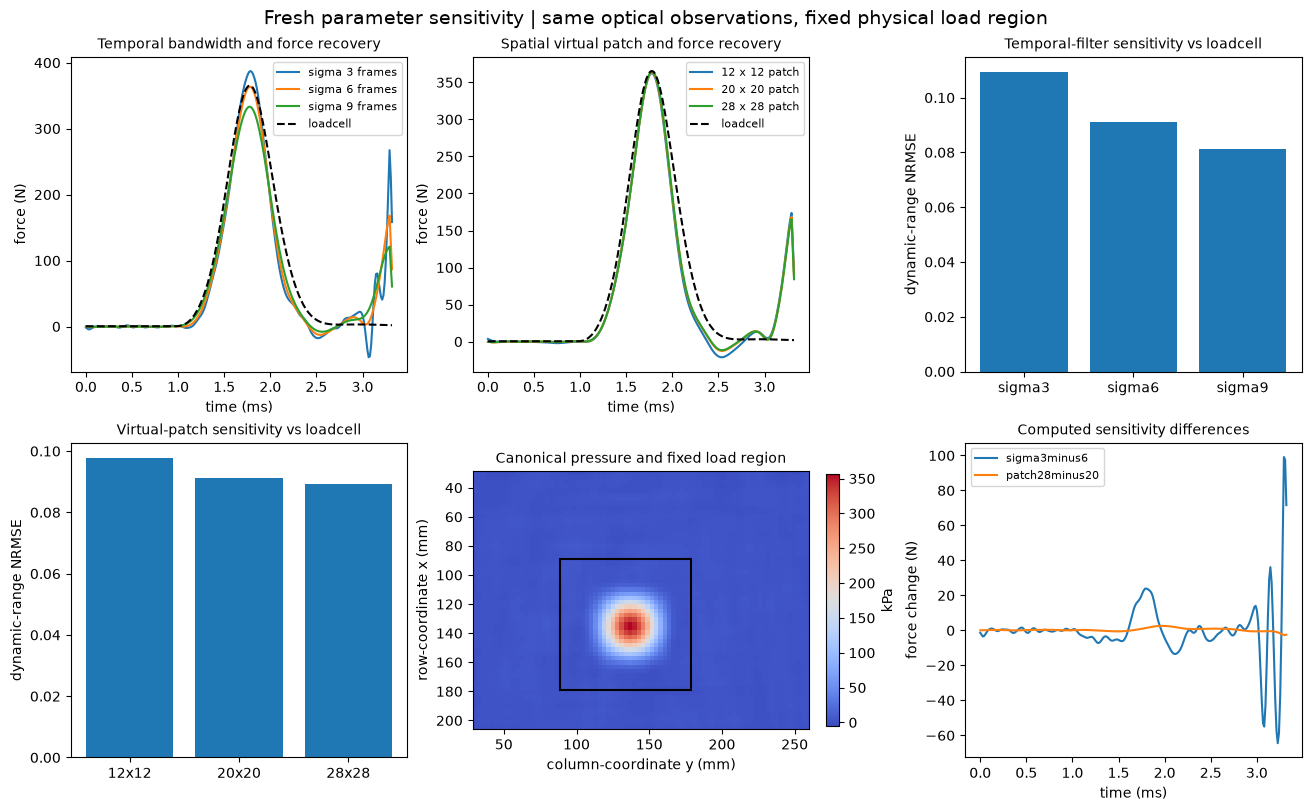

In [7]:
display(figures[4])

## 6. Conclusion

The independent force trace supports localized integrated loading while the poor late-time whole-field integral exposes boundary/artifact sensitivity. Pixel pressure remains a standard-method estimate; the analytic 1% midpoint bias and declared optical integration correction limit exactness claims.

### Scientific interpretation and limits

The measured transient supports a localized force: the source-defined pressure-region integral tracks the independently acquired impact hammer. Whole-field integration has a large late-time error, demonstrating sensitivity to field boundaries, spatially spread reconstruction artifacts and noisy derivatives. The baseline is therefore a standard-method result with experimentally checked integrated force, not exact pixel-pressure truth. Midpoint quadrature has a known1%bias for the analytic quartic test. The minimum optical-integration boundary correction is declared and has a small but measurable displacement effect; it was determined from matrix structure and an analytic ramp, never from force-target tuning.

The observations cover one impact event, small linear-elastic deflection and finite field of view. They do not establish blast-plasticity performance, unique delta-contact pressure, absolute material-property identification or error-free exterior load reconstruction. The dataset text and original code give slightly different density/mirror-distance values; the explicitly selected code calibration is used consistently. No synthetic data or missing-method placeholder is plotted.
